## Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
from IPython.display import clear_output
from scipy.stats import norm

## Product Recommendation Envirnoment with Determinstic Reward and Binary Reward

---

In [2]:
class ProductRecommendationBandit:

    def __init__(self, num_products, recommendation_probabilities, product_rewards):
        if len(recommendation_probabilities) != len(product_rewards):
            raise ValueError("Size of recommendation_probabilities does not match size of product_rewards")

        self.recommendation_probabilities = recommendation_probabilities
        self.product_rewards = product_rewards
        self.num_products = num_products

    def get_recommendation(self, product):
        if not (0 <= product < self.num_products):
            raise ValueError(f"Product index must be between 0 and {self.num_products - 1}")

        return np.random.choice([self.product_rewards[product], 0.0],
                                p=[self.recommendation_probabilities[product], 1 - self.recommendation_probabilities[product]])

### Create Thompson Sampling Agent

In [3]:
class ThompsonSamplingAgent:
  def __init__(self, num_arms):
    self.num_arms = num_arms
    self.alpha = np.ones(self.num_arms)
    self.beta = np.ones(self.num_arms)

  def select_arm(self):
    sampled_probabilities = np.random.beta(self.alpha, self.beta)

    # Choose the arm with the highest sampled probability
    selected_arm = np.argmax(sampled_probabilities)

    return selected_arm

  def update_parameters(self, arm, reward):
    if reward ==1:
      self.alpha[arm] +=1
    else:
      self.beta[arm]+=1

  def run_bandit(self, environment, num_iterations):
    rewards = []
    for iteration in range(num_iterations):
      chosen_arm = self.select_arm()
      reward = environment.get_recommendation(chosen_arm)
      rewards.append(reward)
      self.update_parameters(chosen_arm, reward)

      # Visualize the beta distribution for each arm
      if iteration % 10 ==0:
        self.visualize_beta_distribution(iteration)

    return rewards

  def visualize_beta_distribution(self, iteration):
    clear_output(wait =True)
    plt.figure(figsize = (8,4))
    x = np.linspace(0,1,200)

    for arm in range(self.num_arms):
      y = beta(self.alpha[arm], self.beta[arm])
      plt.plot(x, y.pdf(x), label = f'Arm {arm +1} - {self.alpha[arm]-1} / {self.alpha[arm] + self.beta[arm] -2}')
      plt.fill_between(x, 0, y.pdf(x), alpha= 0.2)

    plt.title(f'Beta Distribution - Iteration {iteration}')
    plt.xlabel('Probability')
    plt.ylabel('Density')
    plt.legend()
    plt.show()



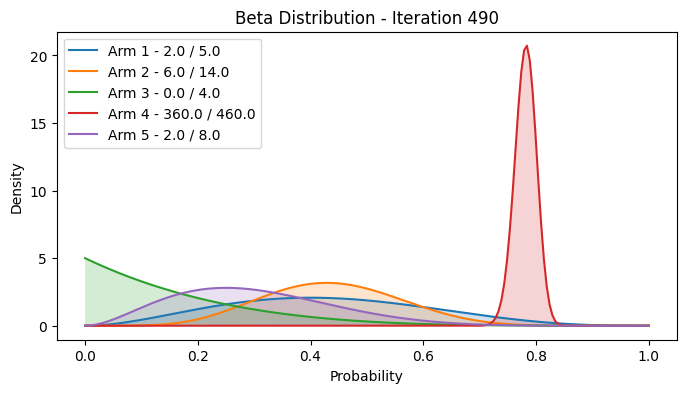

In [4]:
num_products = 5
recommendation_probabilities = [0.2, 0.4, 0.6, 0.8, 0.3]
product_rewards = [1,1,1,1,1]
bandit_env = ProductRecommendationBandit(num_products, recommendation_probabilities, product_rewards)

num_iterations = 500
agent = ThompsonSamplingAgent(num_products)
rewards = agent.run_bandit(bandit_env, num_iterations)

## Product Recommendation Envirnoment with stochastic Reward and Binary Reward

In [5]:
class stochasticProductRecommendationBandit:

    def __init__(self, num_products,  seed= 48):
        self.num_products = num_products

        # Set seed for reproducibility
        np.random.seed(seed)

        # Generate random recommendation probabilities from a Gaussian distribution
        self.recommendation_probabilities = np.clip(np.random.normal(loc=0.5, scale=0.2, size=num_products), 0, 1)

        # Generate random product rewards from a Gaussian distribution, with values not greater than 1
        self.product_rewards = np.clip(np.random.normal(loc=0.5, scale=0.2, size=num_products), 0, 1)

    def get_recommendation(self, product):
        if not (0 <= product < self.num_products):
            raise ValueError(f"Product index must be between 0 and {self.num_products - 1}")

        return np.random.choice([self.product_rewards[product], 0.0],
                                p=[self.recommendation_probabilities[product], 1 - self.recommendation_probabilities[product]])

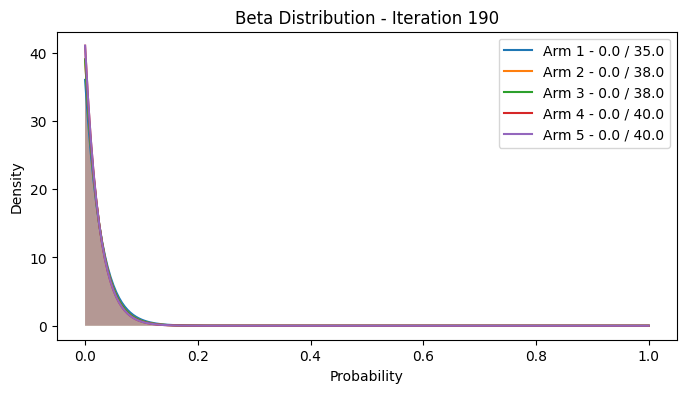

In [6]:
# Example usage:
num_products = 5

bandit = stochasticProductRecommendationBandit(num_products)

num_iterations = 200
agent = ThompsonSamplingAgent(num_products)
rewards = agent.run_bandit(bandit, num_iterations)

## Gaussian Thompson Sampling

In [14]:
class GaussianBanditEnvironment:
  def __init__(self, num_products):
     self.num_products = num_products

     self.true_means = np.random.uniform(1,10, num_products)
     self.true_variances = np.ones(num_products)


  def get_reward(self, product):
    return np.random.normal(self.true_means[product], self.true_variances[product])


In [15]:
class GaussianThompsonSamplingAgent:
  def __init__(self, num_products):
     self.num_products = num_products
     self.estimated_means = np.zeros(self.num_products)
     self.estimated_variances = np.ones(self.num_products) * 100
     self.steps_done = np.zeros(self.num_products)


  def select_arm(self):
    sampled_norm_values = np.random.normal(self.estimated_means, self.estimated_variances)
    selected_arm = np.argmax(sampled_norm_values)

    return selected_arm

  def update_params(self, product, reward):
    mu_est, sigma_est, n_trial = self.estimated_means[product], self.estimated_variances[product], self.steps_done[product]

    #Calculate postrior estimations
    mu_est = mu_est / sigma_est + reward / self.estimated_variances[product]
    sigma_est = 1 /(1/sigma_est + 1 / self.estimated_variances[product])
    mu_est = mu_est * sigma_est
    n_trial +=1

    self.estimated_means[product], self.estimated_variances[product], self.steps_done[product] = mu_est, sigma_est, n_trial

  def visualize_gaussian_distributuion(self, iteration):
    clear_output(wait=True)

    plt.figure(figsize = (8,4))
    x = np.linspace(-10, 20, 200)

    for arm in range(len(self.estimated_means)):
      y = norm(self.estimated_means[arm], self.estimated_variances[arm] ** 0.5)
      plt.plot(x, y.pdf(x), label = f'Arm {arm +1} - {self.estimated_means[arm]:.2f} +/- {self.estimated_variances[arm] **0.5:.2f}')
      plt.fill_between(x,0,y.pdf(x), alpha = 0.2)

    plt.title(f'Gaussian Distributions - Iteration {iteration}')
    plt.xlabel('Reward')
    plt.ylabel('Probability Density')
    plt.legend()
    plt.show()

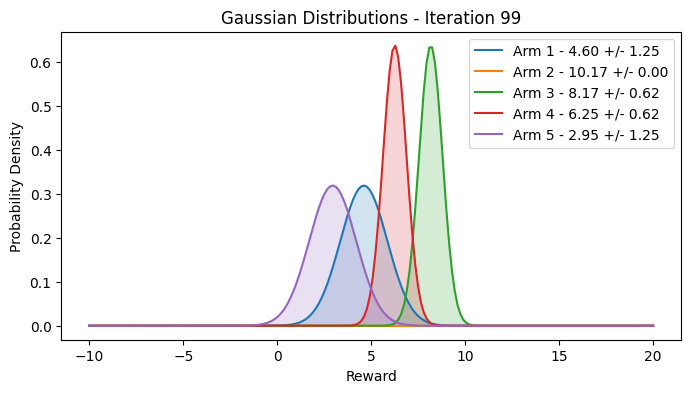

In [16]:
seed_value = 42
np.random.seed(seed_value)

num_products = 5
bandit_env = GaussianBanditEnvironment(num_products)
agent = GaussianThompsonSamplingAgent(num_products)

num_steps = 100
for iteration in range(num_steps):
  selected_product = agent.select_arm()
  reward = bandit_env.get_reward(selected_product)
  agent.update_params(selected_product, reward)

  agent.visualize_gaussian_distributuion(iteration)
